In [1]:
from pathlib import Path
import random
import copy
import numpy as np
import pandas as pd
import joblib

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import TransformerConv, LayerNorm
from torch_geometric.loader import DataLoader

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    hamming_loss, classification_report
)

import matplotlib.pyplot as plt

In [2]:
SEED = 42

EPOCHS = 50
HIDDEN_DIM = 32
DROPOUT = 0.35
HEADS = 4

LEARNING_RATE = 1e-4
BATCH_SIZE = 64
WEIGHT_DECAY = 1e-3

EARLY_STOPPING_PATIENCE = 10

In [3]:
## defining paths

GRAPH_DIR = Path(".")
CHECKPOINT_PATH = Path("transformer_best_model.pt")
METRICS_PATH = Path("transformer_metrics.csv")

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Device: cuda


## 1). Loading Train-val-test graphs

In [5]:
def load_graphs(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")

In [6]:
train_graphs = load_graphs(GRAPH_DIR / "train_graphs.pt")
validation_graphs = load_graphs(GRAPH_DIR / "validation_graphs.pt")
test_graphs = load_graphs(GRAPH_DIR / "test_graphs.pt")

In [7]:
## loading the saved preprocessing objects

preprocessing_objects = joblib.load(
    GRAPH_DIR / "preprocessing_objects.joblib"
)

tactic_encoder = preprocessing_objects["tactic_encoder"]
mitre_encoder = preprocessing_objects["mitre_encoder"]

In [8]:
print("Training graphs:", len(train_graphs))
print("Validation graphs:", len(validation_graphs))
print("Test graphs:", len(test_graphs))
print("Tactic classes:", len(tactic_encoder.classes_))
print("MITRE classes:", len(mitre_encoder.classes_))

Training graphs: 20149
Validation graphs: 2519
Test graphs: 2518
Tactic classes: 13
MITRE classes: 27


## 2). Model Architecture (Hierarchical Edge-Aware Graph Transformer)

Three cascaded prediction heads:

- Binary attack detection
- Multi-label tactic prediction (conditioned on binary)
- Multi-label MITRE technique prediction (conditioned on tactic)

In [9]:
class HierarchicalGraphTransformer(nn.Module):
    def __init__(
        self,
        node_input_dim,
        edge_input_dim,
        hidden_dim,
        tactic_dim,
        mitre_dim,
        heads=4,
        dropout=0.35
    ):
        super().__init__()
        self.dropout = dropout

        # Edge-aware Graph Transformer layers
        self.conv1 = TransformerConv(
            in_channels=node_input_dim,
            out_channels=hidden_dim // heads,
            heads=heads,
            edge_dim=edge_input_dim,
            dropout=dropout,
            beta=True
        )
        self.norm1 = LayerNorm(hidden_dim)

        self.conv2 = TransformerConv(
            in_channels=hidden_dim,
            out_channels=hidden_dim // heads,
            heads=heads,
            edge_dim=edge_input_dim,
            dropout=dropout,
            beta=True
        )
        self.norm2 = LayerNorm(hidden_dim)

        # Shared Edge Representation Trunk
        edge_input_size = hidden_dim * 2 + edge_input_dim
        self.edge_trunk = nn.Sequential(
            nn.Linear(edge_input_size, hidden_dim * 2),
            nn.LayerNorm(hidden_dim * 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU()
        )

        # Cascaded Prediction Heads (Binary -> Tactic -> MITRE Technique)
        self.binary_head = nn.Linear(hidden_dim, 1)

        self.tactic_head = nn.Sequential(
            nn.Linear(hidden_dim + 1, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, tactic_dim)
        )

        self.mitre_head = nn.Sequential(
            nn.Linear(hidden_dim + tactic_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, mitre_dim)
        )

    def forward(self, data):
        x, edge_index, edge_attr = data.x, data.edge_index, data.edge_attr

        x = self.conv1(x, edge_index, edge_attr)
        x = self.norm1(x)
        x = F.gelu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.conv2(x, edge_index, edge_attr)
        x = self.norm2(x)
        x = F.gelu(x)

        src, dst = edge_index[0], edge_index[1]
        raw_edge = torch.cat([x[src], x[dst], edge_attr], dim=1)
        h_edge = self.edge_trunk(raw_edge)

        # Cascade predictions
        binary_logits = self.binary_head(h_edge)  # [E, 1]
        
        tactic_input = torch.cat([h_edge, torch.sigmoid(binary_logits)], dim=1)
        tactic_logits = self.tactic_head(tactic_input)  # [E, 13]

        mitre_input = torch.cat([h_edge, torch.sigmoid(tactic_logits)], dim=1)
        mitre_logits = self.mitre_head(mitre_input)  # [E, 27]

        return binary_logits.squeeze(1), tactic_logits, mitre_logits

## 3). Creating Data Loaders

In [10]:
train_loader = DataLoader(
    train_graphs,
    batch_size=BATCH_SIZE,
    shuffle=True
)

validation_loader = DataLoader(
    validation_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_graphs,
    batch_size=BATCH_SIZE,
    shuffle=False
)

## 4). Defining Optimizer and Instantiating model

In [11]:
example_graph = train_graphs[0]

model = HierarchicalGraphTransformer(
    node_input_dim=example_graph.x.shape[1],
    edge_input_dim=example_graph.edge_attr.shape[1],
    hidden_dim=HIDDEN_DIM,
    tactic_dim=train_graphs[0].y_tactic.shape[1],
    mitre_dim=train_graphs[0].y_mitre.shape[1],
    heads=HEADS,
    dropout=DROPOUT
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print(model)

HierarchicalGraphTransformer(
  (conv1): TransformerConv(22, 8, heads=4)
  (norm1): LayerNorm(32, affine=True, mode=graph)
  (conv2): TransformerConv(32, 8, heads=4)
  (norm2): LayerNorm(32, affine=True, mode=graph)
  (edge_trunk): Sequential(
    (0): Linear(in_features=120, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (6): GELU(approximate='none')
  )
  (binary_head): Linear(in_features=32, out_features=1, bias=True)
  (tactic_head): Sequential(
    (0): Linear(in_features=33, out_features=32, bias=True)
    (1): GELU(approximate='none')
    (2): Dropout(p=0.35, inplace=False)
    (3): Linear(in_features=32, out_features=13, bias=True)
  )
  (mitre_head): Sequential(
    (0): Linear(in_features=45, out_features=32, bias=True)
    (1): GELU(app

## 5). Defining Loss and Training functions

In [12]:
binary_labels = torch.cat([
    graph.y_binary for graph in train_graphs
])

tactic_labels = torch.cat([
    graph.y_tactic for graph in train_graphs
])

mitre_labels = torch.cat([
    graph.y_mitre for graph in train_graphs
])

def softened_pos_weight(labels, max_weight):
    labels = labels.float()
    positives = labels.sum(dim=0)
    negatives = labels.shape[0] - positives
    ratio = negatives / positives.clamp_min(1.0)
    return ratio.sqrt().clamp(
        min=1.0,
        max=max_weight
    ).to(DEVICE)

binary_pos_weight = torch.tensor(1.0, device=DEVICE)
tactic_pos_weight = softened_pos_weight(tactic_labels, max_weight=25.0)
mitre_pos_weight = softened_pos_weight(mitre_labels, max_weight=25.0)

print("Binary weight:", binary_pos_weight)
print("Tactic weights:", tactic_pos_weight)
print("MITRE weights:", mitre_pos_weight)

Binary weight: tensor(1., device='cuda:0')
Tactic weights: tensor([25.0000, 25.0000, 11.2849, 10.6058, 22.0997, 25.0000, 25.0000, 12.1053,
        25.0000, 25.0000, 25.0000,  4.1006, 25.0000], device='cuda:0')
MITRE weights: tensor([25.0000, 25.0000, 25.0000, 25.0000, 25.0000, 25.0000, 10.6249, 11.2944,
        25.0000, 25.0000, 25.0000, 12.1086, 25.0000, 25.0000, 25.0000, 25.0000,
        25.0000, 25.0000, 25.0000, 25.0000, 25.0000, 25.0000, 25.0000, 25.0000,
        25.0000, 25.0000,  4.1240], device='cuda:0')


In [13]:
def get_loss_mask(batch):
    if hasattr(batch, "loss_mask"):
        return batch.loss_mask.bool()
    return torch.ones(
        batch.edge_attr.shape[0],
        dtype=torch.bool,
        device=batch.edge_attr.device
    )

def compute_loss(outputs, batch, loss_mask=None):
    binary_logits, tactic_logits, mitre_logits = outputs

    if loss_mask is None:
        loss_mask = get_loss_mask(batch)

    binary_target = batch.y_binary.float()
    tactic_target = batch.y_tactic.float()
    mitre_target = batch.y_mitre.float()

    binary_loss = F.binary_cross_entropy_with_logits(
        binary_logits[loss_mask],
        binary_target[loss_mask],
        pos_weight=binary_pos_weight
    )

    tactic_loss = F.binary_cross_entropy_with_logits(
        tactic_logits[loss_mask],
        tactic_target[loss_mask],
        pos_weight=tactic_pos_weight
    )

    # Optional guard against missing mitre labels if any
    has_valid_mitre = (binary_target == 0) | (mitre_target.sum(dim=1) > 0)
    mitre_mask = loss_mask & has_valid_mitre

    mitre_loss = F.binary_cross_entropy_with_logits(
        mitre_logits[mitre_mask],
        mitre_target[mitre_mask],
        pos_weight=mitre_pos_weight
    )

    total_loss = (
        0.5 * binary_loss
        + 1.0 * tactic_loss
        + 1.0 * mitre_loss
    )

    return total_loss, binary_loss, tactic_loss, mitre_loss

def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = 0.0
    total_edges = 0

    for batch in loader:
        batch = batch.to(DEVICE)
        optimizer.zero_grad()

        outputs = model(batch)
        loss, _, _, _ = compute_loss(outputs, batch)
        loss.backward()
        optimizer.step()

        selected_edges = int(get_loss_mask(batch).sum().item())
        total_loss += loss.item() * selected_edges
        total_edges += selected_edges

    return total_loss / max(total_edges, 1)

## 6). Evaluation metrics

In [14]:
def safe_roc_auc(y_true, y_score):
    try:
        return roc_auc_score(y_true, y_score)
    except ValueError:
        return np.nan

def safe_average_precision(y_true, y_score):
    try:
        return average_precision_score(y_true, y_score)
    except ValueError:
        return np.nan

def evaluate_model(model, loader, threshold=0.5):
    model.eval()

    all_binary_true = []
    all_binary_prob = []
    all_tactic_true = []
    all_tactic_prob = []
    all_mitre_true = []
    all_mitre_prob = []

    total_loss = 0.0
    total_edges = 0

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            outputs = model(batch)
            loss, _, _, _ = compute_loss(outputs, batch)

            mask = get_loss_mask(batch)
            selected_edges = int(mask.sum().item())
            total_loss += loss.item() * selected_edges
            total_edges += selected_edges

            binary_logits, tactic_logits, mitre_logits = outputs

            all_binary_true.append(batch.y_binary[mask].cpu().numpy())
            all_binary_prob.append(
                torch.sigmoid(binary_logits[mask]).cpu().numpy()
            )
            all_tactic_true.append(batch.y_tactic[mask].cpu().numpy())
            all_tactic_prob.append(
                torch.sigmoid(tactic_logits[mask]).cpu().numpy()
            )
            all_mitre_true.append(batch.y_mitre[mask].cpu().numpy())
            all_mitre_prob.append(
                torch.sigmoid(mitre_logits[mask]).cpu().numpy()
            )

    binary_true = np.concatenate(all_binary_true)
    binary_prob = np.concatenate(all_binary_prob)
    tactic_true = np.concatenate(all_tactic_true)
    tactic_prob = np.concatenate(all_tactic_prob)
    mitre_true = np.concatenate(all_mitre_true)
    mitre_prob = np.concatenate(all_mitre_prob)

    binary_pred = (binary_prob >= threshold).astype(int)
    tactic_pred = (tactic_prob >= threshold).astype(int)
    mitre_pred = (mitre_prob >= threshold).astype(int)

    metrics = {
        "loss": total_loss / max(total_edges, 1),
        "binary_accuracy": accuracy_score(binary_true, binary_pred),
        "binary_precision": precision_score(binary_true, binary_pred, zero_division=0),
        "binary_recall": recall_score(binary_true, binary_pred, zero_division=0),
        "binary_f1": f1_score(binary_true, binary_pred, zero_division=0),
        "binary_roc_auc": safe_roc_auc(binary_true, binary_prob),
        "binary_pr_auc": safe_average_precision(binary_true, binary_prob),
        "tactic_micro_f1": f1_score(tactic_true, tactic_pred, average="micro", zero_division=0),
        "tactic_macro_f1": f1_score(tactic_true, tactic_pred, average="macro", zero_division=0),
        "tactic_hamming_loss": hamming_loss(tactic_true, tactic_pred),
        "tactic_exact_match": np.mean(np.all(tactic_true == tactic_pred, axis=1)),
        "mitre_micro_f1": f1_score(mitre_true, mitre_pred, average="micro", zero_division=0),
        "mitre_macro_f1": f1_score(mitre_true, mitre_pred, average="macro", zero_division=0),
        "mitre_hamming_loss": hamming_loss(mitre_true, mitre_pred),
        "mitre_exact_match": np.mean(np.all(mitre_true == mitre_pred, axis=1))
    }

    outputs = {
        "binary_true": binary_true,
        "binary_prob": binary_prob,
        "tactic_true": tactic_true,
        "tactic_prob": tactic_prob,
        "mitre_true": mitre_true,
        "mitre_prob": mitre_prob
    }

    return metrics, outputs

## 7). Training Loop

In [15]:
best_validation_f1 = -np.inf
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    optimization_loss = train_one_epoch(model, train_loader, optimizer)

    train_metrics, _ = evaluate_model(model, train_loader, threshold=0.5)
    validation_metrics, _ = evaluate_model(model, validation_loader, threshold=0.5)

    row = {
        "epoch": epoch,
        "optimization_loss": optimization_loss,
        "train_loss": train_metrics["loss"],
        "validation_loss": validation_metrics["loss"],
    }

    for metric in [
        "binary_precision",
        "binary_recall",
        "binary_f1",
        "binary_pr_auc",
        "tactic_micro_f1",
        "tactic_macro_f1",
        "mitre_micro_f1",
        "mitre_macro_f1",
    ]:
        row[f"train_{metric}"] = train_metrics[metric]
        row[f"validation_{metric}"] = validation_metrics[metric]

    history.append(row)
    pd.DataFrame(history).to_csv(METRICS_PATH, index=False)

    current_f1 = validation_metrics["binary_f1"]

    if current_f1 > best_validation_f1 + 1e-4:
        best_validation_f1 = current_f1
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "model_config": {
                    "node_input_dim": example_graph.x.shape[1],
                    "edge_input_dim": example_graph.edge_attr.shape[1],
                    "hidden_dim": HIDDEN_DIM,
                    "tactic_dim": train_graphs[0].y_tactic.shape[1],
                    "mitre_dim": train_graphs[0].y_mitre.shape[1],
                    "heads": HEADS,
                    "dropout": DROPOUT,
                },
                "best_validation_f1": best_validation_f1,
                "validation_metrics": validation_metrics,
                "threshold": 0.5,
            },
            CHECKPOINT_PATH,
        )
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['binary_f1']:.4f} | "
        f"Val P: {validation_metrics['binary_precision']:.4f} | "
        f"Val R: {validation_metrics['binary_recall']:.4f} | "
        f"Val F1: {current_f1:.4f} | "
        f"Val AP: {validation_metrics['binary_pr_auc']:.4f}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(f"Early stopping for {EARLY_STOPPING_PATIENCE} epochs.")
        break

print("Best validation binary F1:", round(best_validation_f1, 4))

Epoch 01 | Train Loss: 0.8668 | Val Loss: 0.8700 | Train F1: 0.9383 | Val P: 0.9904 | Val R: 0.9213 | Val F1: 0.9546 | Val AP: 0.9935
Epoch 02 | Train Loss: 0.3268 | Val Loss: 0.3306 | Train F1: 0.9870 | Val P: 0.9881 | Val R: 0.9902 | Val F1: 0.9891 | Val AP: 0.9951
Epoch 03 | Train Loss: 0.1797 | Val Loss: 0.1847 | Train F1: 0.9894 | Val P: 0.9921 | Val R: 0.9904 | Val F1: 0.9913 | Val AP: 0.9957
Epoch 04 | Train Loss: 0.1249 | Val Loss: 0.1310 | Train F1: 0.9914 | Val P: 0.9930 | Val R: 0.9904 | Val F1: 0.9917 | Val AP: 0.9955
Epoch 05 | Train Loss: 0.0971 | Val Loss: 0.1045 | Train F1: 0.9921 | Val P: 0.9939 | Val R: 0.9904 | Val F1: 0.9921 | Val AP: 0.9960
Epoch 06 | Train Loss: 0.0799 | Val Loss: 0.0883 | Train F1: 0.9922 | Val P: 0.9939 | Val R: 0.9904 | Val F1: 0.9921 | Val AP: 0.9965
Epoch 07 | Train Loss: 0.0678 | Val Loss: 0.0779 | Train F1: 0.9929 | Val P: 0.9946 | Val R: 0.9906 | Val F1: 0.9926 | Val AP: 0.9972
Epoch 08 | Train Loss: 0.0591 | Val Loss: 0.0708 | Train F1: 0

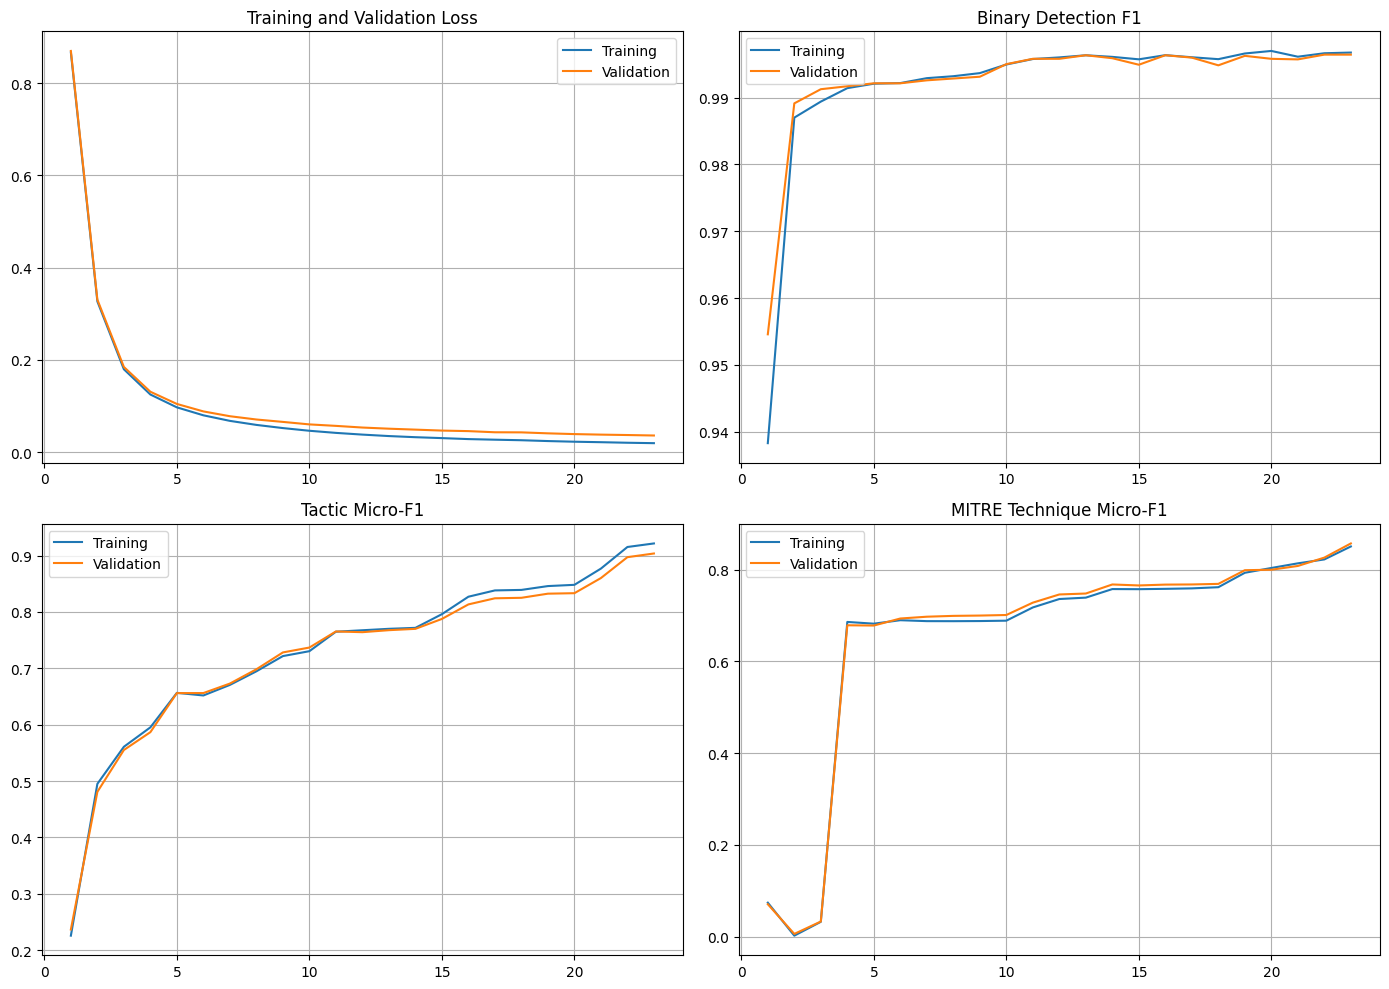

In [16]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(history_df["epoch"], history_df["train_loss"], label="Training")
axes[0, 0].plot(history_df["epoch"], history_df["validation_loss"], label="Validation")
axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(history_df["epoch"], history_df["train_binary_f1"], label="Training")
axes[0, 1].plot(history_df["epoch"], history_df["validation_binary_f1"], label="Validation")
axes[0, 1].set_title("Binary Detection F1")
axes[0, 1].legend()
axes[0, 1].grid(True)

axes[1, 0].plot(history_df["epoch"], history_df["train_tactic_micro_f1"], label="Training")
axes[1, 0].plot(history_df["epoch"], history_df["validation_tactic_micro_f1"], label="Validation")
axes[1, 0].set_title("Tactic Micro-F1")
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].plot(history_df["epoch"], history_df["train_mitre_micro_f1"], label="Training")
axes[1, 1].plot(history_df["epoch"], history_df["validation_mitre_micro_f1"], label="Validation")
axes[1, 1].set_title("MITRE Technique Micro-F1")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

## 8). Evaluating heads on validation and test dataset

In [17]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE)

validation_metrics, _ = evaluate_model(model, validation_loader)
test_metrics, _ = evaluate_model(model, test_loader)

metrics_table = pd.DataFrame([
    {"split": "validation", **validation_metrics},
    {"split": "test", **test_metrics}
])

display(metrics_table.T)
metrics_table.to_csv(METRICS_PATH, index=False)
print("Metrics saved to:", METRICS_PATH)

,0,1
split,validation,test
loss,0.050836,0.046504
binary_accuracy,0.999389,0.995359
binary_precision,0.997145,0.992451
binary_recall,0.995546,0.950617
binary_f1,0.996345,0.971084
binary_roc_auc,0.999349,0.999412
binary_pr_auc,0.998973,0.994324
tactic_micro_f1,0.767642,0.777985
tactic_macro_f1,0.239336,0.238611


Metrics saved to: transformer_metrics.csv
